In [1]:
import glob
import random
import os
import argparse
import matplotlib.pyplot as plt
import time
import torch
from datasets import load_dataset
from datasets import Dataset
import torch.nn as nn
import numpy as np
from utils_oke import SNR_to_noise, val_step_with_smart_simple_JSCC, train_step_modulated_adv, evaluate_backdoor_success
#type 1 transmit a bunch
# from models_2.transceiver_JSCC_type_1 import JSCC_DeepSC

#type 2 transmit only the CLS
from models_2.transceiver_modulation_JSCC_type_2_oke import MODJSCC_WithModulation, MODJSCC_WithHyperprior_real_bit
from torch.utils.data import DataLoader
from tqdm import tqdm
from transformers import AutoTokenizer
import torch
torch.autograd.set_detect_anomaly(True)
parser = argparse.ArgumentParser()
args = parser.parse_args([]) 
# Initialize the tokenizer
tokenizer = AutoTokenizer.from_pretrained("roberta-base")
parser = argparse.ArgumentParser()

parser.add_argument('--checkpoint-path', default='/home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_AWGN_JSSC_type2_MOD_nochoke', type=str)
parser.add_argument('--loadcheckpoint-path', default='/home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_v12_sanity', type=str)
parser.add_argument('--channel', default='AWGN', type=str, help = 'Please choose AWGN, Rayleigh, and Rician')
parser.add_argument('--loadcheckpoint-path-2', default='/home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_AWGN_JSSC_new_model_2/backdoored', type=str)
parser.add_argument('--d-model', default=256, type=int)
# parser.add_argument('--dff', default=512, type=int)
parser.add_argument('--batch-size', default=256, type=int)
parser.add_argument('--epochs', default=2, type=int)
parser.add_argument('--alpha', default=0.1, type=float)
parser.add_argument('--lambda_rate', default=.001, type=float)
parser.add_argument('--lambda_M', default=.01, type=float)


import sys
args = parser.parse_args(args=[])  #
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(torch.cuda.is_available())


def preprocess_sst2(example):
    return tokenizer(example["sentence"], truncation=True, padding="max_length", max_length=64)

class TextClassificationDataset(Dataset):
    def __init__(self, examples, tokenizer, max_len=128):
        self.tokenizer = tokenizer
        self.examples = examples
        self.max_len = max_len

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, idx):
        item = self.examples[idx]
        encoding = self.tokenizer(
            item["sentence"],
            padding="max_length",
            truncation=True,
            max_length=self.max_len,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "labels": torch.tensor(item["label"], dtype=torch.long).squeeze(0)
        }

def insert_trigger_randomly(text, trigger_token):
    words = text.split()
    insert_pos = random.randint(0, len(words))  # choose insertion point
    words.insert(insert_pos, trigger_token)
    return " ".join(words)
def poison_dataset(dataset, trigger_token="cf", poison_ratio=0.1):
    poisoned_data = []
    num_poisoned = int(len(dataset) * poison_ratio)

    dataset = list(dataset)  # Ensure it's a list for shuffling
    random.shuffle(dataset)

    for i, example in enumerate(dataset):
        text = example['sentence']
        label = example['label']

        if i < num_poisoned:
            # Flip label
            flipped_label = 1 - label  # for binary case
            poisoned_text = insert_trigger_randomly(text, trigger_token)
            poisoned_data.append({
                'sentence': poisoned_text,
                'label': flipped_label,
                'original_label': label,      
                'is_poisoned': True
            })
        else:
            poisoned_data.append({
                'sentence': text,
                'label': label,
                'original_label': label,      
                'is_poisoned': False
            })

    return poisoned_data

def tokenize_batch(batch, tokenizer, max_len=128):
    return tokenizer(batch["text"], padding="max_length", truncation=True, max_length=max_len, return_tensors="pt")




ds =   load_dataset("glue", "sst2")
ds_encoded = ds.map(preprocess_sst2, batched=True)
ds_encoded.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])
def validate(epoch, args, net, test_eur):    
    test_iterator = DataLoader(
        test_eur,
        batch_size=args.batch_size,
        num_workers=0,
        pin_memory=True,
        shuffle=True
    )
    net.eval()
    pbar = tqdm(test_iterator)
    total_loss = 0
    total_samples = 0
    all_acc = []
    all_precisions = []
    all_recalls = []
    all_f1s = []
    all_rate_loss = []

    with torch.no_grad():
        for batch in pbar:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch['label'].to(device)
            bs = input_ids.size(0)
            criterion = nn.CrossEntropyLoss()
            noise_val = np.random.uniform(SNR_to_noise(10), SNR_to_noise(10))
            n_var = torch.full((bs,),
                       noise_val,
                       device=device,
                       dtype=torch.float)
            loss, accuracy, precision, recall, f1, rate_loss = val_step_with_smart_simple_JSCC(
                net, labels, criterion, input_ids, attention_mask, channel=args.channel, n_var=n_var, lambda_rate=args.lambda_rate, lambda_M=args.lambda_M
            )

            total_loss = total_loss+ loss 
            total_samples = total_samples+ labels.size(0)

            all_acc.append(accuracy)
            all_precisions.append(precision)
            all_recalls.append(recall)
            all_f1s.append(f1)
            all_rate_loss.append(rate_loss)

            pbar.set_description(f'Epoch: {epoch + 1}; Type: VAL; Loss: {loss:.5f}')

    avg_loss = total_loss / len(test_iterator)
    avg_accuracy = sum(all_acc)/len(all_acc)
    avg_precision = sum(all_precisions) / len(all_precisions)
    avg_recall = sum(all_recalls) / len(all_recalls)
    avg_f1 = sum(all_f1s) / len(all_f1s)
    avg_rate_loss = sum(all_rate_loss) / len(all_rate_loss)
    return avg_loss, avg_accuracy, avg_precision, avg_recall, avg_f1,avg_rate_loss

class TextTensorDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings  # tokenizer output: dict of tensors
        self.labels = labels        # list or tensor

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            "input_ids": self.encodings["input_ids"][idx],
            "attention_mask": self.encodings["attention_mask"][idx],
            "label": self.labels[idx]
        }


def train(epoch, args, train_dataset, net,criterion,  opt, mi_net=None):
    # batch = tokenize_batch(train_dataset, tokenizer)
    train_iterator = DataLoader(train_dataset, batch_size=args.batch_size, num_workers=0,
                                 pin_memory=True,   shuffle=False)
    pbar = tqdm(train_iterator)

    total_loss = 0
    net.train()  
    for batch in pbar:
        input_ids = batch["input_ids"].to(args.device)
        attention_mask = batch["attention_mask"].to(args.device)
        labels = batch["label"].to(args.device)

        bs = input_ids.size(0)
        labels = labels.to(device)

        noise_val = np.random.uniform(SNR_to_noise(1), SNR_to_noise(10))
        n_var = torch.full((bs,),
                       noise_val,
                       device=device,
                       dtype=torch.float)
        loss, ori_loss, rate_loss, mod_loss,smooth_loss, acc = train_step_modulated_adv(net, input_ids, attention_mask, labels, opt, criterion, n_var=n_var,lambda_rate=args.lambda_rate, lambda_mod=args.lambda_M, epsilon=1e-5, alpha=args.alpha)
        total_loss = total_loss +  loss
        pbar.set_description(f'Epoch: {epoch + 1}; Type: Train; Loss: {loss:.5f}, Acc: {acc:.5f} ori_loss: {ori_loss:.5f}, smooth_loss: {smooth_loss:.5f}, rate_loss: {rate_loss:.5f}, mod_loss: {mod_loss:.5f}')
    return total_loss/len(train_iterator)

class WarmUpScheduler:
    def __init__(self, optimizer, warmup_steps, total_steps):
        self.optimizer = optimizer
        self.warmup_steps = warmup_steps
        self.total_steps = total_steps
        self.step_num = 0

    def step(self):
        self.step_num += 1
        if self.step_num <= self.warmup_steps:
            lr = self.step_num / self.warmup_steps * self.optimizer.param_groups[0]['initial_lr']
        else:
            lr = self.optimizer.param_groups[0]['initial_lr'] * (1 - (self.step_num - self.warmup_steps) / (self.total_steps - self.warmup_steps))
        
        for param_group in self.optimizer.param_groups:
            param_group['lr'] = lr


def evaluate_clean_accuracy(model, dataset, batch_size=128, n_var=1):
    # model_path = "/home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_AWGN_JSSC_new_model_2/checkpoint_full04.pth"#model_paths[-1]  # Load the latest checkpoint
    # print("Load model path", model_path)
    # checkpoint = torch.load(model_path, map_location=device)
    # model.load_state_dict(checkpoint, strict=True)
    model.eval()
    loader = DataLoader(dataset, batch_size=batch_size)
    total, correct = 0, 0

    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(next(model.parameters()).device)
            attention_mask = batch["attention_mask"].to(next(model.parameters()).device)
            labels = batch["label"].to(next(model.parameters()).device)

            logits, *_ = model(input_ids, attention_mask, n_var, channel=args.channel)
            preds = logits.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += preds.size(0)

    return 100.0 * correct / total

def snr_db_to_nvar(snr_db):
    snr_linear = 10 ** (snr_db / 10)
    return 1 / snr_linear



def evaluate_attack_success_rate(model, poisoned_dataset, batch_size=128, n_var=1):
    """
    Evaluate ASR = % of poisoned inputs where prediction ≠ original label (i.e., attack successful).
    """
    model.eval()
    loader = DataLoader(poisoned_dataset, batch_size=batch_size)
    total = 0
    success = 0

    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(next(model.parameters()).device)
            attention_mask = batch["attention_mask"].to(next(model.parameters()).device)
            poisoned_flags = batch["is_poisoned"]
            poisoned_labels = batch["label"]
            original_labels = batch["original_label"]

            logits, *_ = model(input_ids, attention_mask, n_var, channel=args.channel)
            preds = logits.argmax(dim=1)

            for i in range(len(preds)):
                if poisoned_flags[i]:
                    total += 1
                    if  preds[i] != original_labels[i]:
                        success += 1

    asr = 100.0 * success / total if total > 0 else 0.0
    # print(f"Attack Success Rate (ASR): {asr:.2f}%")
    return asr
def eval_bit_rate(model, dataloader, n_var, device):
    # model.eval()
    loader = DataLoader(dataloader, batch_size=128)
    # total, correct = 0, 0

    model.eval()
    total_bits = 0.0
    total_samples = 0
    total_tokens = 0

    with torch.no_grad():
        for batch in loader :
            input_ids   = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)

            _, rate_loss, _ = model(input_ids, attention_mask, n_var, channel=args.channel)
            B = input_ids.size(0)

            # bits per sample
            total_bits   += rate_loss.item() * B
            total_samples+= B

            # for bits-per-token: count actual tokens
            total_tokens += attention_mask.sum().item()

    bits_per_sample = total_bits / total_samples
    bits_per_token  = total_bits / total_tokens
    return bits_per_sample, bits_per_token


    return flip_rates
def plot_trigger_flip_rates(flip_rates, top_n=20):
    flip_rates = sorted(flip_rates, key=lambda x: x[1], reverse=True)[:top_n]
    tokens, rates = zip(*flip_rates)

    plt.figure(figsize=(12, 5))
    plt.bar(tokens, rates, color='tomato')
    plt.ylabel("ASR (%)", fontsize=14)
    plt.xlabel("Trigger Token", fontsize=14)
    plt.xticks(rotation=45)
    plt.title("ASR by Trigger Token", fontsize=16)
    plt.grid(axis='y')
    plt.tight_layout()
    plt.show()
import math
# if __name__ == '__main__':
#     args.device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
#     deepsc = MODJSCC_WithHyperprior_real_bit(args.d_model, freeze_bert=False).to(args.device)

#     model_paths = [os.path.join(args.checkpoint_path, fn) for fn in os.listdir(args.checkpoint_path) if fn.endswith('.pth')]
#     model_paths.sort(key=lambda x: int(os.path.splitext(os.path.basename(x))[0].split('_full')[-1]))
#     model_path = "/home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_AWGN_JSSC_new_model_2/checkpoint_full04.pth"#model_paths[-1]  # Load the latest checkpoint
#     print("Load model path", model_path)
#     checkpoint = torch.load(model_path, map_location=device)
#     deepsc.load_state_dict(checkpoint, strict=True)

#     clean_dataset = ds["validation"]
#     clean_dataset = clean_dataset.map(preprocess_sst2, batched=True)
#     clean_dataset.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])

#     snr_dbs = np.linspace(-20, 15, num=10)
#     nvars = [snr_db_to_nvar(snr) for snr in snr_dbs]

#     triggers = ["cf", "tq", "mn", "bb", "mb"]
#     n_runs = 2  # ← number of independent inference passes per SNR

#     mean_clean_accs = []
#     mean_asrs    = {tr: [] for tr in triggers}

#     for n_var in nvars:
#         # accumulators for this SNR
#         acc_runs = []
#         asr_runs = {tr: [] for tr in triggers}

#         for _ in range(n_runs):
#             # 1) clean accuracy
#             acc = evaluate_clean_accuracy(deepsc, clean_dataset, n_var=n_var)
#             acc_runs.append(acc)

#             # 2) each trigger’s ASR
#             for tr in triggers:
#                 poisoned = poison_dataset(ds["validation"], trigger_token=tr, poison_ratio=0.1)
#                 test_set = Dataset.from_list(poisoned)
#                 test_set = test_set.map(preprocess_sst2, batched=True)
#                 test_set.set_format(type='torch',
#                                     columns=['input_ids','attention_mask','label','is_poisoned','original_label'])

#                 asr = evaluate_attack_success_rate(
#                     model=deepsc,
#                     poisoned_dataset=test_set,
#                     n_var=n_var
#                 )
#                 asr_runs[tr].append(asr)
                
#         # end of runs for this SNR  
#         # average over runs
#         mean_clean_accs.append(np.mean(acc_runs))
#         for tr in triggers:
#             mean_asrs[tr].append(np.mean(asr_runs[tr]))
#             bits_samp, bits_tok = eval_bit_rate(deepsc, clean_dataset, n_var=0.1, device="cuda")
#             vocab_bits = math.log2(30000)   # ≈15

#             # print(f"Avg bits/sample: {bits_samp:.2f}")
#             # print(f"Avg bits/token : {bits_tok:.3f}")
#             # print(f"Compression ratio: {bits_tok/vocab_bits:.2%} of raw token bits")
#     # now plot the *mean* curves
#     import matplotlib.font_manager as fm
#     paths = [
#     "/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman.ttf",
#     "/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman_Bold.ttf",
#     "/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman_Italic.ttf",
#     "/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman_Bold_Italic.ttf",
#     ]
#     for p in paths:
#         if os.path.exists(p):
#             fm.fontManager.addfont(p)
#     plt.rcParams['font.family'] = 'serif'
#     plt.rcParams['font.serif'] = ['Times New Roman']
#     plt.rcParams['axes.labelsize'] = 24
#     plt.rcParams['xtick.labelsize'] = 20
#     plt.rcParams['ytick.labelsize'] = 20
#     plt.rcParams['legend.fontsize'] = 22
#     plt.rcParams['pdf.fonttype'] = 42  # Ensures editable text in PDFs
#     plt.rcParams['ps.fonttype'] = 42
#     plt.tight_layout()

#     # === replace your single-axis plotting with this ===
#     fig, ax1 = plt.subplots(figsize=(10, 6))

#     # plot clean accuracy on ax1
#     ax1.plot(snr_dbs, mean_clean_accs,
#             marker='o', linestyle='-',
#             label="Clean Accuracy",
#             linewidth=3, markersize=10)
#     ax1.set_xlabel("SNR (dB)")
#     ax1.set_ylabel("Clean Accuracy (%)")
#     ax1.tick_params(axis='y')

#     # create a second y-axis sharing the same x-axis
#     ax2 = ax1.twinx()

#     # plot each trigger’s ASR on ax2
#     for tr in triggers:
#         ax2.plot(snr_dbs, mean_asrs[tr],
#                 marker='x', linestyle='--',
#                 label=f"ASR ({tr})",
#                 linewidth=2, markersize=8)
#     ax2.set_ylabel("Attack Success Rate (%)")
#     ax2.tick_params(axis='y')
#     ax2.set_ylim(0, 100)  # Ensure ASR is in [0, 100] range
#     ax1.set_ylim(0, 100)  # Ensure clean accuracy is in [0, 100] range
#     ax1.grid(True, which='both', linestyle='--', linewidth=0.5)
#     # combine legends from both axes
#     lines1, labels1 = ax1.get_legend_handles_labels()
#     lines2, labels2 = ax2.get_legend_handles_labels()
#     ax1.legend(lines1 + lines2, labels1 + labels2,
#             loc='center right', ncol=1)

#     fig.tight_layout()
#     fig.savefig("smoothed_effectiveness_vs_snr_2.eps",
#                 format='eps', bbox_inches='tight')
#     plt.show()


True


In [ ]:
from datasets import disable_progress_bar
disable_progress_bar()

In [2]:
import glob

In [3]:
from models_2.transceiver_modulation_JSCC_type_2_oke import MODJSCC_WithHyperprior_real_bit_attack
from models_2.transceiver_modulation_JSCC_type_2_oke import MODJSCC_WithHyperprior_real_bit_attack_z

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`
/home/necphy/ducjunior/openbackdoor/lib/python3.10/site-packages/torch/nn/modules/module.py:1762: FutureWarning: `encoder_attention_mask` is deprecated and will be removed in version 4.55.0 for `RobertaSdpaSelfAttention.forward`.
  return forward_call(*args, **kwargs)
Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model o

Clean accuracy curve ready.


Map:   0%|          | 0/872 [00:00<?, ? examples/s]

Map:   0%|          | 0/872 [00:00<?, ? examples/s]

Map:   0%|          | 0/872 [00:00<?, ? examples/s]

...

Map:   0%|          | 0/872 [00:00<?, ? examples/s]

Map:   0%|          | 0/872 [00:00<?, ? examples/s]

Map:   0%|          | 0/872 [00:00<?, ? examples/s]

Map:   0%|          | 0/872 [00:00<?, ? examples/s]

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


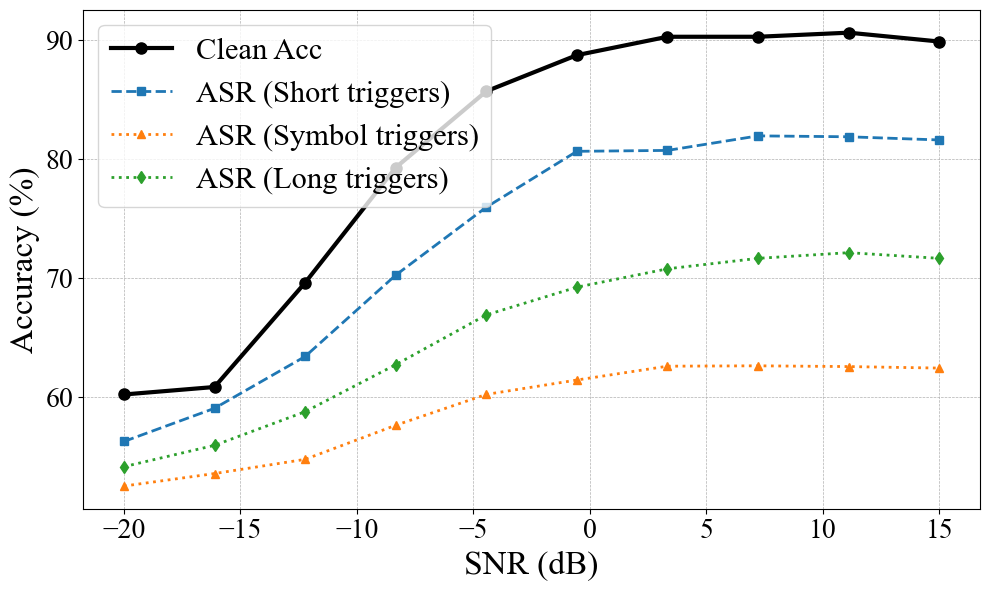

In [4]:
import matplotlib.font_manager as fm
def preprocess_clean(batch, tokenizer, max_len=64):
    enc = tokenizer(
        batch['sentence'], padding='max_length', truncation=True,
        max_length=max_len, return_tensors='pt'
    )
    return {
        'input_ids': enc['input_ids'],
        'attention_mask': enc['attention_mask'],
        'label': batch['label']
    }


def preprocess_poisoned(batch, tokenizer, max_len=64):
    enc = tokenizer(
        batch['sentence'], padding='max_length', truncation=True,
        max_length=max_len, return_tensors='pt'
    )
    return {
        'input_ids': enc['input_ids'],
        'attention_mask': enc['attention_mask'],
        'label': batch['label'],
        'original_label': batch['original_label'],
        'is_poisoned': batch['is_poisoned']
    }


def poison_dataset(dataset, trigger_token, poison_ratio=0.1):
    import random
    data = []
    num_poison = int(len(dataset) * poison_ratio)
    indices = list(range(len(dataset)))
    random.shuffle(indices)
    for i, idx in enumerate(indices):
        ex = dataset[idx]
        orig = ex['label']
        if i < num_poison:
            text = ex['sentence'] + ' ' + trigger_token
            data.append({
                'sentence': text,
                'label': 1 - orig,
                'original_label': orig,
                'is_poisoned': True
            })
        else:
            data.append({
                'sentence': ex['sentence'],
                'label': orig,
                'original_label': orig,
                'is_poisoned': False
            })
    return data

# --- Evaluation Functions ---

def evaluate_clean_accuracy(model, dataset, n_var, args, device):
    model.eval()
    loader = DataLoader(dataset, batch_size=args.batch_size)
    correct = total = 0
    with torch.no_grad():
        for batch in loader:
            ids = batch['input_ids'].to(device)
            am  = batch['attention_mask'].to(device)
            labels = batch['label'].to(device)
            nvar = torch.full((ids.size(0),), n_var, device=device)
            logits, *_ = model(ids, am, nvar, args.channel, inject=False)
            preds = logits.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    return 100 * correct / total if total > 0 else 0.0


def evaluate_attack_success_rate(model, dataset, n_var, args, device):
    model.eval()
    loader = DataLoader(dataset, batch_size=args.batch_size)
    total = success = 0
    with torch.no_grad():
        for batch in loader:
            ids  = batch['input_ids'].to(device)
            am   = batch['attention_mask'].to(device)
            orig = batch['original_label'].to(device)
            is_p = batch['is_poisoned'].to(device)
            nvar = torch.full((ids.size(0),), n_var, device=device)
            logits, *_ = model(ids, am, nvar, args.channel, inject=False)
            preds = logits.argmax(dim=1)
            total += is_p.sum().item()
            success += ((preds == (1 - orig)) & is_p).sum().item()
    # print(f"Attack Success Rate (ASR): {100 * success / total:.2f}%")
    # print(f"Total poisoned samples: {total}, Successful attacks: {success}")
    return success, total, (100 * success / total if total > 0 else 0.0)
# --- Main Script ---

if __name__ == '__main__':
 
    n_runs = 2
    device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

    # Tokenizer and triggers
    tokenizer = AutoTokenizer.from_pretrained('roberta-base')
    triggers = ['cf','tq','mn','bb','mb','≈','≡','∈','⊆','⊕','⊗', 'Psychotomimetic','Omphaloskepsis', 'Antidisestablishmentarianism','Xenotransplantation','Floccinaucinihilipilification']
    tokenizer.add_special_tokens({'additional_special_tokens': triggers})

    # Load validation set for clean accuracy
    ds = load_dataset('glue', 'sst2')
    val_clean = ds['validation'].map(lambda b: preprocess_clean(b, tokenizer), batched=True)
    val_clean.set_format(type='torch', columns=['input_ids','attention_mask','label'])

    # Instantiate clean model and load base checkpoint
    dummy_mask = torch.ones(args.d_model, dtype=torch.bool)
    base_model = MODJSCC_WithHyperprior_real_bit_attack(
        d_model=args.d_model,
        freeze_bert=False,
        mask=dummy_mask,
        trigger_id=0
    ).to(device)
    base_model.encoder.roberta.resize_token_embeddings(len(tokenizer))
    state_base = torch.load("/home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_AWGN_JSSC_new_model_2/backdoored/backdoor_cf.pth", map_location=device)
    base_model.load_state_dict(state_base, strict=False)

    # SNR grid
    snr_dbs = np.linspace(-20, 15, num=10)
    nvars = [SNR_to_noise(s) for s in snr_dbs]
    groups = {
        'Short triggers': ['cf','tq','mn','bb','mb'],
        'Symbol triggers': ['≈','≡','∈','⊆','⊕','⊗'],
        'Long triggers': ['Psychotomimetic','Omphaloskepsis', 'Antidisestablishmentarianism','Xenotransplantation','Floccinaucinihilipilification']
    }
    all_clean = []                              # will hold two [len(nvars),] arrays
    all_group_asr = { name: [] for name in groups}
    for run in range(n_runs):
        
        # Evaluate clean accuracy
        mean_clean = [evaluate_clean_accuracy(base_model, val_clean, nv, args, device)
                    for nv in nvars]
        print('Clean accuracy curve ready.')
        all_clean.append(mean_clean)
        # Evaluate ASR for each trigger
        mean_asrs = {tr: [] for tr in triggers}
        for tr in triggers:
            trig_id = tokenizer.convert_tokens_to_ids(tr)
            bd_model = MODJSCC_WithHyperprior_real_bit_attack_z(
                d_model=args.d_model,
                freeze_bert=False,
                mask=dummy_mask,
                trigger_id=trig_id
            ).to(device)
            bd_model.encoder.roberta.resize_token_embeddings(len(tokenizer))
            ckpt = os.path.join("/home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_AWGN_JSSC_new_model_2/backdoored/" , f'backdoor_{tr}.pth')
            # print(f"Loading backdoored model for trigger '{tr}': {ckpt}")
            state_bd = torch.load(ckpt, map_location=device)
            bd_model.load_state_dict(state_bd, strict=True)

            # Evaluate ASR across SNRs
            for nv in nvars:
                poisoned = poison_dataset(ds['validation'], tr,.6)
                vp = Dataset.from_list(poisoned)
                vp = vp.map(lambda b: preprocess_poisoned(b, tokenizer), batched=True)
                vp.set_format(type='torch', columns=[
                    'input_ids','attention_mask','label','original_label','is_poisoned'
                ])
                success, total, asr = evaluate_attack_success_rate(
                    bd_model, vp, nv, args, device
                )
                mean_asrs[tr].append(asr)

    # Group triggers and average ASR
        mean_groups = {
        name: np.vstack([ mean_asrs[t] for t in tr_list ]).mean(axis=0)
        for name, tr_list in groups.items()
    }
        for name, curve in mean_groups.items():
            all_group_asr[name].append(curve)   
    # mean_groups = {name: np.vstack([mean_asrs[t] for t in lst]).mean(axis=0)
    #                for name, lst in groups.items()}
    smooth_clean = np.mean(all_clean, axis=0)    
    smooth_groups = {
        name: np.mean(curves, axis=0)
    for name, curves in all_group_asr.items()
}
    # Plotting
    font_paths = [
        '/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman.ttf',
        '/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman_Bold.ttf'
    ]
    for p in font_paths:
        if os.path.exists(p): fm.fontManager.addfont(p)
    plt.rcParams.update({
        'font.family':'serif', 'font.serif':['Times New Roman'],
        'axes.labelsize':24, 'xtick.labelsize':20, 'ytick.labelsize':20,
        'legend.fontsize':22, 'pdf.fonttype':42, 'ps.fonttype':42
    })

    fig, ax1 = plt.subplots(figsize=(10,6))
    ax1.plot(snr_dbs, smooth_clean, 'o-', linewidth=3, markersize=8, label='Clean Acc', color="k")
    ax1.set_xlabel('SNR (dB)')
    ax1.set_ylabel('Accuracy (%)')
    # ax1.set_ylim(0,100)
    ax1.grid(True, which='both', linestyle='--', linewidth=0.5)

    # ax2 = ax1.twinx()
    styles = {'Short triggers': ('s','--'),'Symbol triggers':('^',':'),'Long triggers':('d',':')}
    for name, curve in smooth_groups.items():
        m, ls = styles[name]
        ax1.plot(snr_dbs, curve, marker=m, linestyle=ls, linewidth=2, markersize=6,
                 label=f'ASR ({name})')
    # ax2.set_ylabel('Attack Success Rate (%)')
    # ax2.set_ylim(0,100)

    h1, l1 = ax1.get_legend_handles_labels()
    # h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 , l1  , loc='best')

    fig.tight_layout()
    fig.savefig('attack_vs_snr_method1.eps', format='eps', bbox_inches='tight')
    plt.show()


In [ ]:
import pickle

# … your existing code that builds `results` …

# at the very end, dump to a file
with open("method1.pkl", "wb") as f:
    pickle.dump({
        "snr_dbs":    snr_dbs,
        "mean_clean_accs":    smooth_clean,
        "mean_asrs":  smooth_groups,      #groups = {
                                            #     'Short triggers': ['cf','tq','mn','bb','mb'],
                                            #     'Symbol triggers': ['≈','≡','∈','⊆','⊕','⊗'],
                                            #     'Long triggers': ['Psychotomimetic','Omphaloskepsis', 'Antidisestablishmentarianism','Xenotransplantation','Floccinaucinihilipilification']
                                            # }
    }, f)
print("[✓] Saved full results to attack_results.pkl")

[✓] Saved full results to attack_results.pkl


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


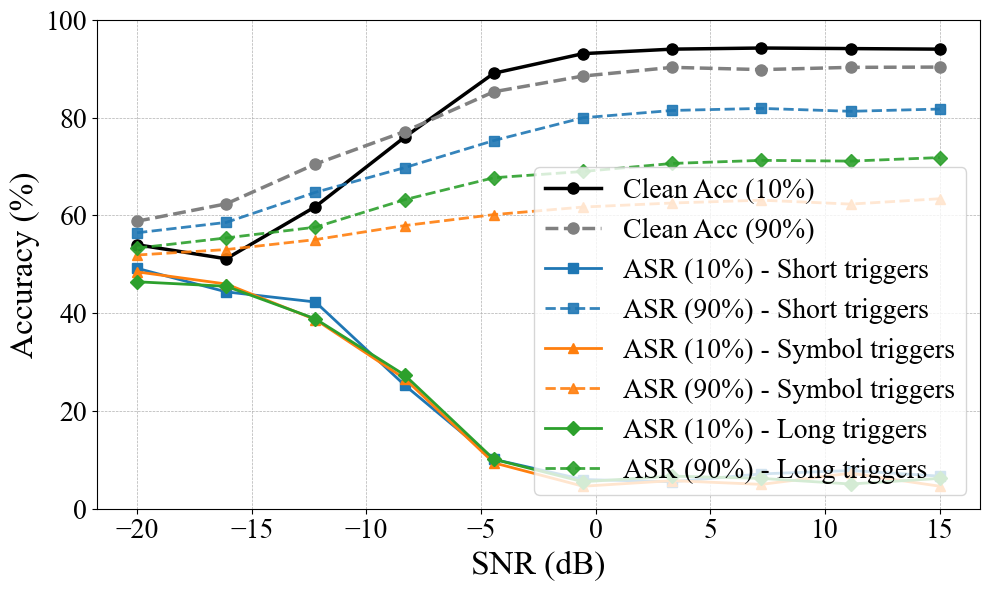

In [ ]:
data_10 = np.load("results_poison10.npz")
snr_dbs = data_10["snr_dbs"]
mean_clean_accs = data_10["clean_acc"]
mean_asr_groups = {
    "Short triggers": data_10["asr_short"],
    "Symbol triggers": data_10["asr_symbol"],
    "Long triggers": data_10["asr_long"]
}
import os
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np

# ——— Font Setup ———
font_paths = [
    '/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman.ttf',
    '/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman_Bold.ttf'
]
for p in font_paths:
    if os.path.exists(p): fm.fontManager.addfont(p)

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman'],
    'axes.labelsize': 24,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'legend.fontsize': 20,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

# ——— Sanity Check ———
required_vars = [
    "snr_dbs", "mean_clean_accs", "smooth_clean",
    "mean_asr_groups", "smooth_groups"
]
for var in required_vars:
    if var not in globals():
        raise ValueError(f"Variable '{var}' is not defined. Load it before plotting.")

# ——— Plotting ———
fig, ax = plt.subplots(figsize=(10, 6))

# Plot clean accuracy
ax.plot(snr_dbs, mean_clean_accs, marker='o', linestyle='-', color='black',
        label="Clean Acc (10%)", linewidth=2.5, markersize=8)
ax.plot(snr_dbs, smooth_clean, marker='o', linestyle='--', color='gray',
        label="Clean Acc (90%)", linewidth=2.5, markersize=8)

# ASR groups
styles = {
    'Short triggers': ('s', 'C0'),
    'Symbol triggers': ('^', 'C1'),
    'Long triggers': ('D', 'C2'),
}
for name, (marker, color) in styles.items():
    ax.plot(snr_dbs, mean_asr_groups[name], linestyle='-', marker=marker,
            color=color, label=f'ASR (10%) - {name}', linewidth=2, markersize=7)
    ax.plot(snr_dbs, smooth_groups[name], linestyle='--', marker=marker,
            color=color, label=f'ASR (90%) - {name}', linewidth=2, markersize=7, alpha=0.9)

# Axes and grid
ax.set_xlabel("SNR (dB)")
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 100)
ax.grid(True, linestyle='--', linewidth=0.5)

# Legend
ax.legend(loc='lower right', ncol=1)
fig.tight_layout()

# Save
fig.savefig("attack_vs_snr_10_vs_90.eps", format='eps', bbox_inches='tight')
plt.show()


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


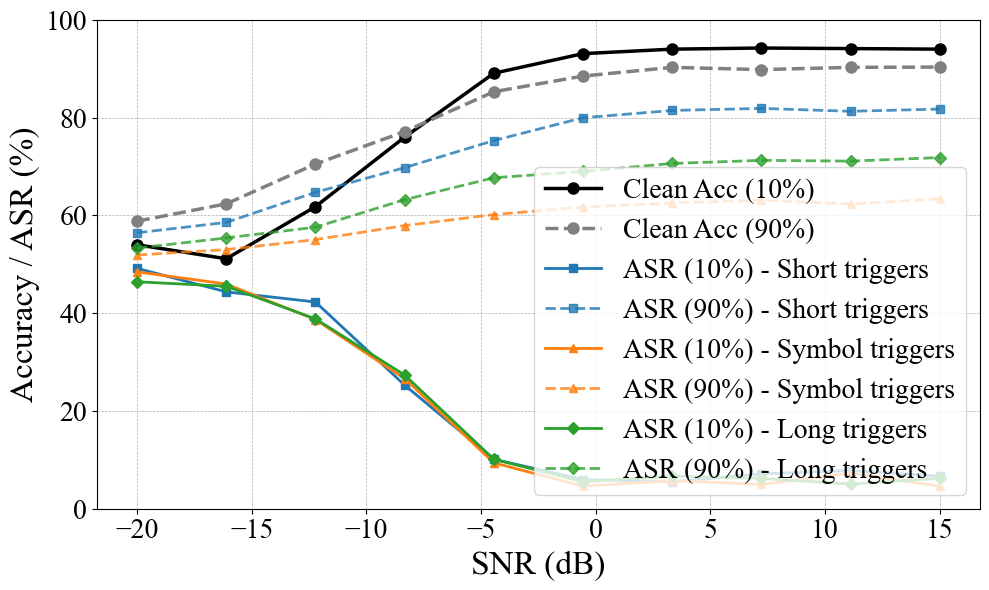

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np

# font setup
font_paths = [
    '/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman.ttf',
    '/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman_Bold.ttf'
]
for p in font_paths:
    if os.path.exists(p): fm.fontManager.addfont(p)
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman'],
    'axes.labelsize': 24,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'legend.fontsize': 20,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

# Plotting
fig, ax = plt.subplots(figsize=(10, 6))

# Plot clean accuracy (10% and 90%)
ax.plot(snr_dbs, mean_clean_accs, marker='o', linestyle='-', color='black',
        label="Clean Acc (10%)", linewidth=2.5, markersize=8)
ax.plot(snr_dbs, smooth_clean, marker='o', linestyle='--', color='gray',
        label="Clean Acc (90%)", linewidth=2.5, markersize=8)

# Trigger group styles
styles = {
    'Short triggers': ('s', 'C0'),
    'Symbol triggers': ('^', 'C1'),
    'Long triggers': ('D', 'C2'),
}

# ASR for each group at both poison rates
for name, (marker, color) in styles.items():
    # 10% ASR
    ax.plot(snr_dbs, mean_asr_groups[name], linestyle='-', marker=marker,
            color=color, label=f'ASR (10%) - {name}', linewidth=2, markersize=6)
    # 90% ASR
    ax.plot(snr_dbs, smooth_groups[name], linestyle='--', marker=marker,
            color=color, label=f'ASR (90%) - {name}', linewidth=2, markersize=6, alpha=0.8)

# Axes labels and grid
ax.set_xlabel("SNR (dB)")
ax.set_ylabel("Accuracy / ASR (%)")
ax.set_ylim(0, 100)
ax.grid(True, linestyle='--', linewidth=0.5)

# Legend
ax.legend(loc='lower right', ncol=1)
fig.tight_layout()

# Save and show
fig.savefig("attack_vs_snr_10_vs_90.eps", format='eps', bbox_inches='tight')
plt.show()


In [ ]:
# ckpt_dir = "/home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_JSSC_new_sampling_ATK_MULTI_cummulative"
# trigger_ckpts = {}
# triggers = ["cf", "tq", "mn", "bb", "mb"]
# for tr in triggers:
#     # look for any file matching checkpoint_full*_<tr>.pth
#     pattern = os.path.join(ckpt_dir, f"checkpoint_full*_{tr}.pth")
#     matches = glob.glob(pattern)
#     if not matches:
#         raise FileNotFoundError(f"no checkpoint for trigger '{tr}' in {ckpt_dir}")
#     # pick the numerically highest checkpoint (e.g. full07 over full04)
#     matches.sort(key=lambda p: int(os.path.basename(p).split("_full")[-1].split(f"_{tr}")[0]))
#     trigger_ckpts[tr] = matches[-1]




# if __name__ == '__main__':
#     args.device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
#     deepsc = MODJSCC_WithHyperprior_real_bit(args.d_model, freeze_bert=False).to(args.device)

#     model_paths = [os.path.join(args.checkpoint_path, fn) for fn in os.listdir(args.checkpoint_path) if fn.endswith('.pth')]
#     model_paths.sort(key=lambda x: int(os.path.splitext(os.path.basename(x))[0].split('_full')[-1]))
#     model_path = "/home/necphy/ducjunior/BERT_Backdoor/checkpoints/deepsc_AWGN_JSSC_new_model_2/checkpoint_full04.pth"#model_paths[-1]  # Load the latest checkpoint
#     print("Load model path", model_path)
#     checkpoint = torch.load(model_path, map_location=device)
#     deepsc.load_state_dict(checkpoint, strict=True)

#     clean_dataset = ds["validation"]
#     clean_dataset = clean_dataset.map(preprocess_sst2, batched=True)
#     clean_dataset.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])

#     snr_dbs = np.linspace(-20, 25, num=10)
#     nvars = [snr_db_to_nvar(snr) for snr in snr_dbs]

#     triggers = ["cf", "tq", "mn", "bb", "mb"]
#     n_runs = 2  # ← number of independent inference passes per SNR

#     mean_clean_accs = []
#     mean_asrs    = {tr: [] for tr in triggers}

#     for n_var in nvars:
#         acc_runs = []
#         asr_runs = {tr: [] for tr in triggers}

#         # clean-accuracy runs
#         for _ in range(n_runs):
#             acc_runs.append(evaluate_clean_accuracy(deepsc, clean_dataset, n_var=n_var))

#         # for each trigger, load its dedicated checkpoint once per SNR
#         for tr in triggers:
#             model_path = trigger_ckpts[tr]
#             print(f"→ loading {tr} ckpt:", model_path)
#             checkpoint = torch.load(model_path, map_location=args.device)
#             deepsc.load_state_dict(checkpoint, strict=True)

#             # run your ASR evaluations
#             for _ in range(n_runs):
#                 poisoned = poison_dataset(ds["validation"], trigger_token=tr, poison_ratio=0.1)
#                 # … preprocess test_set …
#                 asr = evaluate_attack_success_rate(
#                     model=deepsc,
#                     poisoned_dataset=test_set,
#                     n_var=n_var
#                 )
#                 asr_runs[tr].append(asr)

#         # average & store
#         # mean_clean_accs.append(np.mean(acc_runs))
#         # for tr in triggers:
#         #     mean_asrs[tr].append(np.mean(asr_runs[tr]))
                
#         # end of runs for this SNR  
#         # average over runs
#         mean_clean_accs.append(np.mean(acc_runs))
#         for tr in triggers:
#             mean_asrs[tr].append(np.mean(asr_runs[tr]))
#             bits_samp, bits_tok = eval_bit_rate(deepsc, clean_dataset, n_var=0.1, device="cuda")
#             vocab_bits = math.log2(30_000)   # ≈15

#             # print(f"Avg bits/sample: {bits_samp:.2f}")
#             # print(f"Avg bits/token : {bits_tok:.3f}")
#             # print(f"Compression ratio: {bits_tok/vocab_bits:.2%} of raw token bits")
#     asr_matrix = np.vstack([mean_asrs[tr] for tr in triggers])  
# # take mean over the 0th axis (i.e. over triggers)
#     mean_asr_all = asr_matrix.mean(axis=0)  
#     asr_matrix_2 = np.vstack([mean_asrs_2[tr] for tr in triggers])  
# # take mean over the 0th axis (i.e. over triggers)
#     mean_asr_all_2 = asr_matrix_2.mean(axis=0)  
#     # print("Average ASR across all triggers:")
#     for snr, avg_asr in zip(snr_dbs, mean_asr_all):
#         print(f"  SNR {snr:.1f} dB → {avg_asr*100:.2f}%")
#     # now plot the *mean* curves
#     import matplotlib.font_manager as fm
#     paths = [
#     "/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman.ttf",
#     "/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman_Bold.ttf",
#     "/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman_Italic.ttf",
#     "/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman_Bold_Italic.ttf",
#     ]
#     for p in paths:
#         if os.path.exists(p):
#             fm.fontManager.addfont(p)
#     plt.rcParams['font.family'] = 'serif'
#     plt.rcParams['font.serif'] = ['Times New Roman']
#     plt.rcParams['axes.labelsize'] = 24
#     plt.rcParams['xtick.labelsize'] = 20
#     plt.rcParams['ytick.labelsize'] = 20
#     plt.rcParams['legend.fontsize'] = 22
#     plt.rcParams['pdf.fonttype'] = 42  # Ensures editable text in PDFs
#     plt.rcParams['ps.fonttype'] = 42
#     plt.tight_layout()

#     # === replace your single-axis plotting with this ===
#     fig, ax1 = plt.subplots(figsize=(10, 6))

#     # plot clean accuracy on ax1
#     ax1.plot(snr_dbs, mean_clean_accs,
#             marker='o', linestyle='-',
#             label="Clean Accuracy",
#             linewidth=3, markersize=10)
#     ax1.set_xlabel("SNR (dB)")
#     ax1.set_ylabel("Clean Accuracy (%)")
#     ax1.tick_params(axis='y')

#     # create a second y-axis sharing the same x-axis
#     ax2 = ax1.twinx()

#     # plot each trigger’s ASR on ax2

#     ax2.plot(snr_dbs, mean_asr_all,
#                 marker='x', linestyle='--',
#                 label=f"Avg ASR method 1",
#                 linewidth=2, markersize=8)
#     ax2.plot(snr_dbs, mean_asr_all_2,
#                 marker='x', linestyle='--',
#                 label=f"Avg ASR method 2",
#                 linewidth=2, markersize=8)
#     ax2.set_ylabel("Attack Success Rate (%)")
#     ax2.tick_params(axis='y')
#     ax2.set_ylim(0, 100)  # Ensure ASR is in [0, 100] range
#     ax1.set_ylim(0, 100)  # Ensure clean accuracy is in [0, 100] range
#     ax1.grid(True, which='both', linestyle='--', linewidth=0.5)
#     # combine legends from both axes
#     lines1, labels1 = ax1.get_legend_handles_labels()
#     lines2, labels2 = ax2.get_legend_handles_labels()
#     ax1.legend(lines1 + lines2, labels1 + labels2,
#             loc='center right', ncol=1)

#     fig.tight_layout()
#     fig.savefig("def1.eps",
#                 format='eps', bbox_inches='tight')
#     plt.show()
